This tutorial presents an example of seasonal streamflow forecasting using the ***Ensemble Streamflow Prediction (ESP)*** method. In summary, this method assumes that historical sequences of precipitation and other meteorological variables, resampled for the same dates for which the forecast is being produced, are representative of the meteorological conditions that will occur in the future. These sequences are used as input data for a hydrological model with updated initial conditions, i.e., representative of the current state of the basin.

The scripts below are based on the original methodology presented in:

*   *Day, G. N. (1985). Extended streamflow forecasting using NWSRFS. Journal of Water Resources Planning and Management, 111(2), 157-170.*

In this example, we will apply traditional (standard) ESP, in which each past year of the meteorological data series represents a possible future scenario.

---

# **SETUP**

## S1: (OPTIONAL) Enable interactive plots with `Matplotlib`

If we want to enable interactive plots with `Matplotlib`, we can install the `ipympl` package. The lines below are adapted for installation in **Google Colab**, while other platforms for running Python notebooks on a local machine (**Jupyter**, **Visual Studio**) may require some modifications for `ipympl` to work. For more details, see https://matplotlib.org/ipympl/.

There are also other plotting libraries (e.g., `plotly`) that support interactive plots and could be used as an alternative.

In [1]:
# Install only if interactive graphs (zoom, pan) with matplotlib are desired
!pip install -q ipympl
get_ipython().kernel.do_shutdown(restart=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.0/519.0 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 29.5 MB/s eta 0:00:00


{'status': 'ok', 'restart': True}

The previous cell contains a command that **forces a runtime restart**, which ensures the script works properly in Google Colab. You'll get a notification that your session crashed. THIS IS OK! We must **wait for the system to reconnect** before running the cell below and the following scripts in this tutorial. If you want to "run all" at the top, you'll need to comment this cell out.

In [1]:
# Load matplotlib to use the magic command
from matplotlib import pyplot as plt
# Load widget manager
from google.colab import output
output.enable_custom_widget_manager()

 # Magic command to turn on interactive graphs in matplotlib
%matplotlib ipympl

## S2: Cloning a hydrological model repository

We will clone the *simple_water_balance* repository from the large-scale hydrology group (HGE/UFRGS), hosted on `GitHub`. We will do this in order to use a Python script for a simplified hydrological model.

Note: To use the `git clone` command on a platform for running notebooks/Python scripts on a local machine (e.g., **Jupyter**, **Visual Studio Code**), you need to make sure Git is installed on your computer. If it is not, Git can be downloaded from (https://git-scm.com/downloads)

In [2]:
!git clone https://github.com/HGE-IPH/simple_water_balance.git

Cloning into 'simple_water_balance'...
remote: Enumerating objects: 36, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (33/33), done.
remote: Total 36 (delta 12), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (36/36), 227.34 KiB | 942.00 KiB/s, done.
Resolving deltas: 100% (12/12), done.


## S3: Install the hydromodel package (this may take a while)

In [3]:
# Install only if hydromodel is not already available
import importlib.util

if importlib.util.find_spec("hydromodel") is None:
    print("Installing hydromodel...")
    !pip install -q hydromodel
    get_ipython().kernel.do_shutdown(restart=True)
else:
    print("hydromodel is already installed")

Installing hydromodel...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 5.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 7.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 3.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.1/56.1 kB 4.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.9/108.9 kB 9.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.6/185.6 kB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.3/204.3 kB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.7/117.7 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.2/64.2 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 82.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.7/310

## S4: Import Python Libraries

Let's import the additional libraries needed to carry out the tutorial

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime
from scipy.optimize import differential_evolution
from hydromodel.models.gr4j import gr4j

## S5: Create Folders

Create an output folder in the root directory where we will export the results:

In [2]:
# Define folder path (e.g., in the current working directory)
folder_output = 'output'

# Create the folder if it doesn't exist
os.makedirs(folder_output, exist_ok=True)

---

# **1. Read the data**





We will read the .csv files containing daily data for precipitation (P), streamflow (Q), and potential evapotranspiration (PET). Each .csv file must have 2 columns (one with the dates and another with the variable's values), in addition to:

* The title of the date column defined as '*Date*' (without quotes)
* The dates in **YYYY-MM-DD** format

## 1.1 Set file paths

In [3]:
# Set file paths
file_P_path = './simple_water_balance/input_example/P_42395000.csv'
file_PET_path = './simple_water_balance/input_example/PET_42395000.csv'
file_Q_path = './simple_water_balance/input_example/Q_42395000.csv'

## 1.2 Format the data

In [4]:
# Catchment area in km²
catchment_area = 13000

df_p = pd.read_csv(file_P_path, index_col='Date')
df_pet = pd.read_csv(file_PET_path, index_col='Date')
df_q = pd.read_csv(file_Q_path, index_col='Date')

df_p.index = pd.to_datetime(df_p.index)
df_pet.index = pd.to_datetime(df_pet.index)
df_q.index = pd.to_datetime(df_q.index)

# Combine the three dataframes by date
data = pd.concat(
    [
        df_p["P"].rename("P"),
        df_pet["PET"].rename("PET"),
        df_q.iloc[:, 0].rename("Qobs_m3s"),
    ],
    axis=1,
)

# Ensure chronological order
data = data.sort_index()

# P and PET cannot be missing when running GR4J
data = data.dropna(subset=["P", "PET"])

# Replace negative P and PET with zero
data["P"] = data["P"].clip(lower=0)
data["PET"] = data["PET"].clip(lower=0)

# Negative observed flows are treated as missing
data.loc[data["Qobs_m3s"] < 0, "Qobs_m3s"] = np.nan

print(data.head())
print()
print("Period:", data.index.min(), "to", data.index.max())
print("Number of days:", len(data))
print("Missing observed flows:", data["Qobs_m3s"].isna().sum())

                P   PET  Qobs_m3s
Date                             
1980-01-01  10.56  4.36    592.39
1980-01-02  14.64  3.29    622.84
1980-01-03   4.14  5.47    662.82
1980-01-04   0.52  7.45    674.09
1980-01-05   0.10  7.25    625.03

Period: 1980-01-01 00:00:00 to 2024-12-31 00:00:00
Number of days: 16437
Missing observed flows: 0


Additional considerations for the hydrological model to work correctly:

* The P, PET, and Q data series must have a **compatible period** (same start and end dates)
* The **P and PET series must not contain missing data**
* If there is **no Q data** for the entire period covered by the meteorological data, the streamflow .csv file must still contain **all the dates**, and the data corresponding to the missing dates must be left empty.

## 1.3 Plot #
daily P, PET, and Q series:

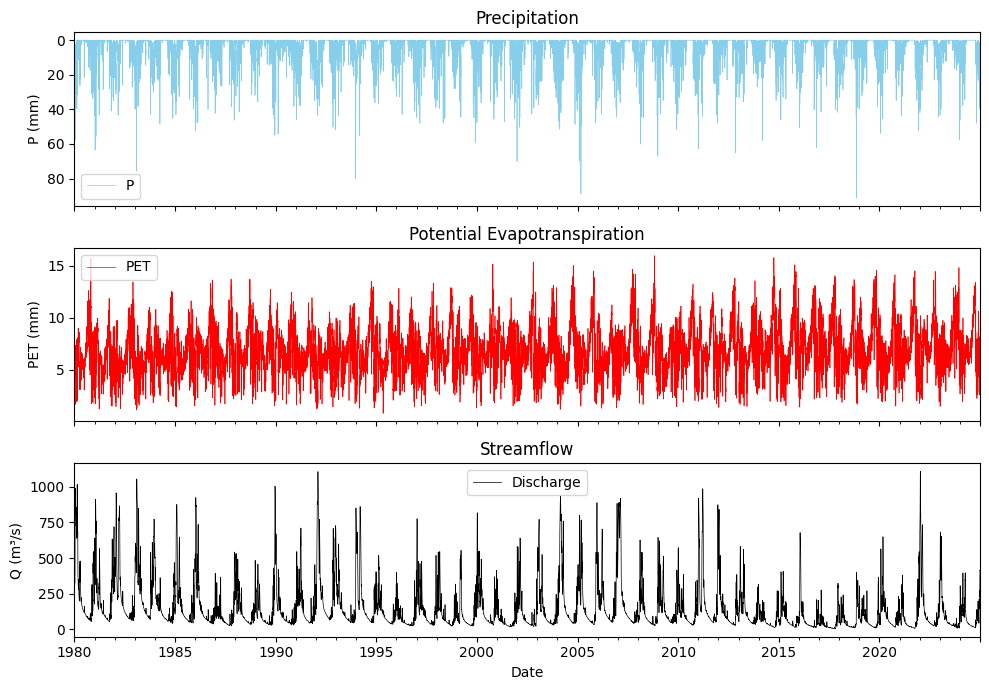

In [5]:
# Plot data:
fig, axes = plt.subplots(3,1, sharex=True, figsize=(10, 7))

axes = axes.flatten()

df_p.plot(ax=axes[0], linewidth=0.5, color='skyblue', ylabel='P (mm)', title='Precipitation')
df_pet.plot(ax=axes[1], linewidth=0.5, color='red', ylabel='PET (mm)', title='Potential Evapotranspiration')
df_q.plot(ax=axes[2], linewidth=0.5, color='k', ylabel='Q (m³/s)', title='Streamflow')

# Use inverted y for precipitation
axes[0].invert_yaxis()

plt.tight_layout()
plt.show()

---

# **2. The GR4J hydrological model**

## 2.1 About GR4J

For this ESP-based forecasting example, we will use a lumped catchment hydrological model, `GR4J`. The name stands for Génie Rural à 4 paramètres Journalier - A daily model with 4 parameters. This model is developed by `INRAE` in the airGR suite. https://webgr.inrae.fr/eng/tools/hydrological-models/daily-hydrological-model-gr4j It is natively in R, but we can use it in Python using the Hydromodel package we have installed.

The GR4J model has 4 parameters:

X1 : the production store maximal capacity (mm),

X2 : the catchment water exchange coefficient (mm/day),

X3 : the one-day maximal capacity of the routing reservoir (mm),

X4 : the HU1 unit hydrograph time base (days).

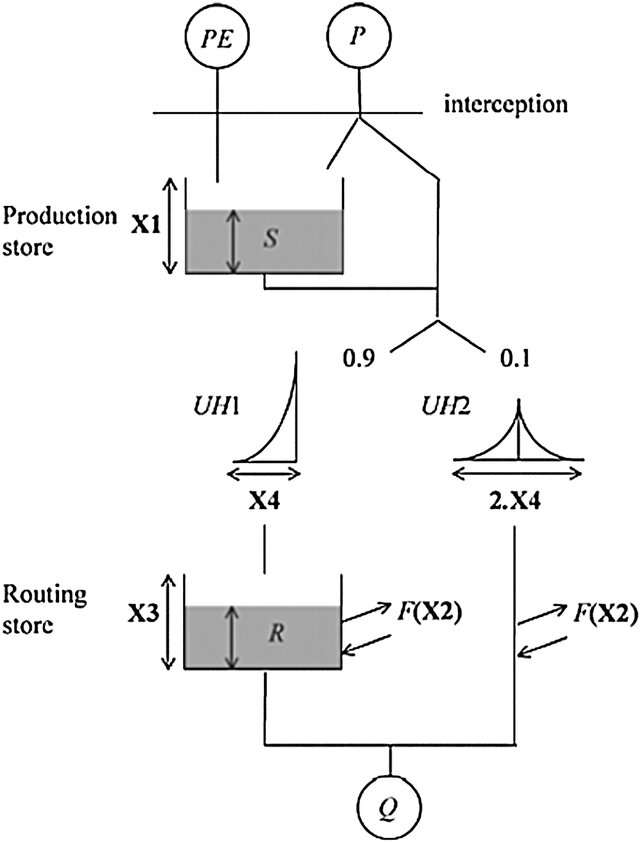

## 2.2 Convert observed flow to runoff depth

GR4J’s simulated values are runoff depth in mm/day. The conversion is:

$$ q = \frac{Q \times 86.4}{A} $$ where: \begin{aligned} q &= \text{runoff (mm day}^{-1}\text{)} \\ Q &= \text{discharge (m}^3\text{ s}^{-1}\text{)} \\ A &= \text{catchment area (km}^2\text{)} \end{aligned}

In [6]:
def m3s_to_mmday(q_m3s, area_km2):
    """Convert discharge from m³/s to runoff depth in mm/day."""
    return q_m3s * 86.4 / area_km2

def mmday_to_m3s(q_mmday, area_km2):
    """Convert runoff depth from mm/day to discharge in m³/s."""
    return q_mmday * area_km2 / 86.4

data["Qobs_mmday"] = m3s_to_mmday(
    data["Qobs_m3s"],
    catchment_area,
)

data[["Qobs_m3s", "Qobs_mmday"]].describe()

,Qobs_m3s,Qobs_mmday
count,16437.000000,16437.000000
mean,147.651929,0.981317
std,172.141794,1.144081
min,3.790000,0.025189
25%,47.440000,0.315294
50%,82.890000,0.550900
75%,168.370000,1.119013
max,1108.700000,7.368591


---

# **3. Run the hydrological simulation**

import the model from the "hydromodel" package https://pypi.org/project/hydromodel/0.2.7/

In [7]:
from hydromodel.models import gr4j
from hydromodel import calibrate, simulate, evaluate

/usr/local/lib/python3.13/dist-packages/hydrodatasource/configs/config.py:141: UserWarning: Using default data paths in home directory: /root/hydrodatasource_data
  _init_settings()


Define the function that runs GR4J. Returns simulated runoff in mm/day, excluding the warm-up period.


In [8]:
from hydromodel.models.gr4j import gr4j

def run_gr4j(p, pet, parameters, warmup_length=365):

    p = np.asarray(p, dtype=np.float64).reshape(-1)
    pet = np.asarray(pet, dtype=np.float64).reshape(-1)

    if p.shape != pet.shape:
        raise ValueError(
            f"P and PET must have identical shapes. "
            f"Found P={p.shape}, PET={pet.shape}."
        )

    if not np.isfinite(p).all():
        raise ValueError("P contains missing or infinite values.")

    if not np.isfinite(pet).all():
        raise ValueError("PET contains missing or infinite values.")

    if len(p) <= warmup_length:
        raise ValueError(
            f"The series has {len(p)} days, but warm-up is "
            f"{warmup_length} days."
        )

    # Shape required by hydromodel:
    # [time, basin, variable]
    forcing = np.column_stack([p, pet])
    forcing = forcing[:, np.newaxis, :]

    # Shape required by hydromodel:
    # [basin, parameter]
    parameter_array = np.asarray(
        parameters,
        dtype=np.float64
    ).reshape(1, 4)

    # IMPORTANT: gr6j returns (streamflow, actual_ET)
    streamflow, actual_et = gr4j(
        p_and_e=forcing,
        parameters=parameter_array,
        warmup_length=warmup_length,
        normalized_params=False,
        return_state=False,
    )

    # streamflow shape is:
    # [time after warm-up, basin, output]
    qsim = streamflow[:, 0, 0]

    return qsim

## 3.1 Calibrate the model

Set the Calibration/Validation period

In [9]:
# Example periods: change these to match your available record
cal_start = "1980-01-01"
cal_end   = "2005-12-31"

val_start = "2006-01-01"
val_end   = "2020-12-31"

cal_data = data.loc[cal_start:cal_end].copy()
val_data = data.loc[val_start:val_end].copy()

print("Calibration period:")
print(cal_data.index.min(), "to", cal_data.index.max())
print("Days:", len(cal_data))

print("\nValidation period:")
print(val_data.index.min(), "to", val_data.index.max())
print("Days:", len(val_data))

Calibration period:
1980-01-01 00:00:00 to 2005-12-31 00:00:00
Days: 9497

Validation period:
2006-01-01 00:00:00 to 2020-12-31 00:00:00
Days: 5479


If those dates fall outside the data record, use an automatic split instead:

In [10]:
split_point = int(len(data) * 0.7)

cal_data = data.iloc[:split_point].copy()
val_data = data.iloc[split_point:].copy()

print("Calibration:", cal_data.index.min(), "to", cal_data.index.max())
print("Validation:", val_data.index.min(), "to", val_data.index.max())

Calibration: 1980-01-01 00:00:00 to 2011-07-01 00:00:00
Validation: 2011-07-02 00:00:00 to 2024-12-31 00:00:00


Set some test parameters, and run a short simulation to check the functions are working.

In [11]:
test_parameters = [
    500.0,   # x1
    0.0,     # x2
    100.0,   # x3
    2.0,     # x4
]

warmup_length = 365*4 #365 days is one year of warmup, here we use 4 years

test_qsim = run_gr4j(
    p=cal_data["P"].values,
    pet=cal_data["PET"].values,
    parameters=test_parameters,
    warmup_length=warmup_length,
)

print("Input length:", len(cal_data))
print("Warm-up length:", warmup_length)
print("Output length:", len(test_qsim))
print("Expected output length:", len(cal_data) - warmup_length)
print("First simulated values:", test_qsim[:5])
print("All values finite:", np.isfinite(test_qsim).all())

/usr/local/lib/python3.13/dist-packages/hydromodel/models/gr4j.py:401: RuntimeWarning: Parameter metadata for model 'gr4j' was not provided. Falling back to MODEL_PARAM_DICT defaults.
  model_param_dict = get_model_param_config("gr4j", kwargs)


Input length: 11505
Warm-up length: 1460
Output length: 10045
Expected output length: 10045
First simulated values: [2.24749234 2.64467649 2.72458293 2.36629857 2.12131807]
All values finite: True


Define the function that will calibrate the model, using the Kling Gupta Efficiency as an evaluation metric.


## 3.2 Kling-Gupta Efficiency (KGE)

The Kling-Gupta Efficiency (KGE) is a commonly used metric for evaluating hydrological model performance. It combines three aspects of model skill into a single score:

1. **Correlation** between observed and simulated flows.
2. **Bias** in the mean flow.
3. **Bias** in the variability of flows.

The KGE is defined as:

$$
KGE = 1 - \sqrt{
(r - 1)^2 +
(\alpha - 1)^2 +
(\beta - 1)^2
}
$$

where:

- $r$ = Pearson correlation coefficient between observed and simulated flows
- $\alpha = \frac{\sigma_{sim}}{\sigma_{obs}}$ = ratio of simulated and observed standard deviations
- $\beta = \frac{\mu_{sim}}{\mu_{obs}}$ = ratio of simulated and observed mean flows

### Interpretation

| KGE | Interpretation |
|------|---------------|
| 1.0 | Perfect agreement |
| > 0.8 | Very good performance |
| 0.6 - 0.8 | Good performance |
| 0.4 - 0.6 | Moderate performance |
| < 0.4 | Poor performance |
| < 0 | Worse than simply matching the observed mean |

### Why use KGE?

Unlike the Nash-Sutcliffe Efficiency (NSE), which mainly focuses on matching the hydrograph shape, KGE explicitly balances:

- Timing of flows (correlation)
- Mean water balance (bias)
- Variability and flow range (standard deviation)

This makes KGE particularly useful for model calibration when both flow dynamics and water balance are important.

### Use in this notebook

During calibration, the optimisation algorithm searches for the GR4J parameter set that maximises KGE.

Because `differential_evolution()` minimises an objective function, we return the negative KGE:

$$
Objective = -KGE
$$

For example:

| KGE | Objective Value |
|------|------|
| 0.90 | -0.90 |
| 0.75 | -0.75 |
| 0.25 | -0.25 |

The optimiser therefore finds the parameter set that produces the highest KGE.

Invalid parameter sets are assigned a large penalty value so that the optimiser avoids them.

In [12]:
def kge(obs, sim):
    r = np.corrcoef(obs, sim)[0, 1]
    alpha = np.std(sim) / np.std(obs)
    beta = np.mean(sim) / np.mean(obs)

    return 1 - np.sqrt(
        (r - 1)**2 +
        (alpha - 1)**2 +
        (beta - 1)**2
    )

In [13]:
# any weird behaviour outputs a PENALTY score of 1000000
PENALTY = 1e6

def calibration_objective(parameters):
    try:
        qsim = run_gr4j(
            p=cal_data["P"].values,
            pet=cal_data["PET"].values,
            parameters=parameters,
            warmup_length=warmup_length,
        )

        # The simulation starts after the warm-up period
        qobs = cal_data["Qobs_mmday"].values[warmup_length:]

        if len(qsim) != len(qobs):
            raise ValueError(
                f"Length mismatch: qsim={len(qsim)}, qobs={len(qobs)}"
            )

        valid = np.isfinite(qobs) & np.isfinite(qsim)

        if valid.sum() < 30:
            return PENALTY

        score = kge(
            qobs[valid],
            qsim[valid]
        )

        if not np.isfinite(score):
            return PENALTY
# NOTICE HERE IT RETURNS A NEGATIVE SCORE,
# this is because the differential evolution algorithm used below minimises the score
# but KGE should be a high value (1) for the best fit. We return it to positive later.
        return -float(score)

    except Exception as error:
        # Prevent one invalid parameter set stopping the calibration
        print(
            "Invalid parameters:",
            np.round(parameters, 3),
            "|",
            type(error).__name__,
            str(error),
        )
        return PENALTY



In [14]:
from scipy.optimize import differential_evolution

parameter_bounds = [
    (10.0, 2500.0),   # x1: production store capacity, mm
    (-10.0, 10.0),    # x2: groundwater exchange, mm/day
    (1.0, 1000.0),    # x3: routing store capacity, mm
    (0.5, 20.0),      # x4: unit hydrograph time base, days
]
calibration_result = differential_evolution(
    func=calibration_objective,
    bounds=parameter_bounds,
    seed=42,
    popsize=5,
    maxiter=5,
    polish=False,
    workers=1,
    updating="immediate",
    disp=True,
)

print(calibration_result)

differential_evolution step 1: f(x)= -0.6930957042081733


/usr/local/lib/python3.13/dist-packages/hydromodel/models/gr4j.py:401: RuntimeWarning: Parameter metadata for model 'gr4j' was not provided. Falling back to MODEL_PARAM_DICT defaults.
  model_param_dict = get_model_param_config("gr4j", kwargs)


differential_evolution step 2: f(x)= -0.744391634944282
differential_evolution step 3: f(x)= -0.744391634944282
differential_evolution step 4: f(x)= -0.7528416951224097
differential_evolution step 5: f(x)= -0.7746309791168651
             message: Maximum number of iterations has been exceeded.
             success: False
                 fun: -0.7746309791168651
                   x: [ 1.845e+03  8.840e+00  2.480e+02  4.562e+00]
                 nit: 5
                nfev: 120
          population: [[ 1.845e+03  8.840e+00  2.480e+02  4.562e+00]
                       [ 1.227e+03  6.115e+00  7.114e+02  1.065e+01]
                       ...
                       [ 2.139e+03  7.026e+00  2.554e+02  1.215e+01]
                       [ 1.228e+03  5.224e+00  8.768e+02  2.826e+00]]
 population_energies: [-7.746e-01 -6.522e-01 ... -5.983e-01 -6.579e-01]


In [15]:
calibration_result = differential_evolution(
    func=calibration_objective,
    bounds=parameter_bounds,
    seed=42,
    popsize=10,
    maxiter=40,
    tol=0.001,
    polish=True,
    workers=1,
    updating="immediate",
    disp=True,
)

best_parameters = calibration_result.x

best_parameter_dict = dict(
    zip(
        ["x1", "x2", "x3", "x4", "x5", "x6"],
        best_parameters,
    )
)

print("\nBest parameters")

for name, value in best_parameter_dict.items():
    print(f"{name}: {value:.4f}")

print(f"\nCalibration KGE: {-calibration_result.fun:.3f}")

differential_evolution step 1: f(x)= -0.6650715293502782
differential_evolution step 2: f(x)= -0.7625522268581827
differential_evolution step 3: f(x)= -0.7930179362158014
differential_evolution step 4: f(x)= -0.7930179362158014
differential_evolution step 5: f(x)= -0.7930179362158014
differential_evolution step 6: f(x)= -0.8589978378004581
differential_evolution step 7: f(x)= -0.8589978378004581
differential_evolution step 8: f(x)= -0.8589978378004581
differential_evolution step 9: f(x)= -0.8589978378004581
differential_evolution step 10: f(x)= -0.8589978378004581
differential_evolution step 11: f(x)= -0.8589978378004581
differential_evolution step 12: f(x)= -0.8589978378004581
differential_evolution step 13: f(x)= -0.8589978378004581
differential_evolution step 14: f(x)= -0.8589978378004581
differential_evolution step 15: f(x)= -0.8589978378004581
differential_evolution step 16: f(x)= -0.8589978378004581
differential_evolution step 17: f(x)= -0.8589978378004581
differential_evolution 

In [16]:
cal_data["Qsim_mmday"] = np.nan

cal_qsim = run_gr4j(
    p=cal_data["P"].values,
    pet=cal_data["PET"].values,
    parameters=best_parameters,
    warmup_length=warmup_length,
)

cal_data.loc[
    cal_data.index[warmup_length:],
    "Qsim_mmday"
] = cal_qsim

/usr/local/lib/python3.13/dist-packages/hydromodel/models/gr4j.py:401: RuntimeWarning: Parameter metadata for model 'gr4j' was not provided. Falling back to MODEL_PARAM_DICT defaults.
  model_param_dict = get_model_param_config("gr4j", kwargs)


In [17]:
val_data["Qsim_mmday"] = np.nan

val_qsim = run_gr4j(
    p=val_data["P"].values,
    pet=val_data["PET"].values,
    parameters=best_parameters,
    warmup_length=warmup_length,
)

val_data.loc[
    val_data.index[warmup_length:],
    "Qsim_mmday"
] = val_qsim


/usr/local/lib/python3.13/dist-packages/hydromodel/models/gr4j.py:401: RuntimeWarning: Parameter metadata for model 'gr4j' was not provided. Falling back to MODEL_PARAM_DICT defaults.
  model_param_dict = get_model_param_config("gr4j", kwargs)


In [18]:
cal_data["Qsim_m3s"] = mmday_to_m3s(
    cal_data["Qsim_mmday"],
    catchment_area,
)

val_data["Qsim_m3s"] = mmday_to_m3s(
    val_data["Qsim_mmday"],
    catchment_area,
)

3.4. Plotting the graph with the observed and simulated streamflow series, along with the performance metrics:

In [19]:
def nse(obs, sim):
    obs = np.asarray(obs)
    sim = np.asarray(sim)

    mask = ~np.isnan(obs) & ~np.isnan(sim)
    obs = obs[mask]
    sim = sim[mask]

    return 1 - np.sum((sim - obs) ** 2) / np.sum((obs - np.mean(obs)) ** 2)


def percent_bias(obs, sim):
    obs = np.asarray(obs)
    sim = np.asarray(sim)

    mask = ~np.isnan(obs) & ~np.isnan(sim)
    obs = obs[mask]
    sim = sim[mask]

    return 100 * np.sum(sim - obs) / np.sum(obs)

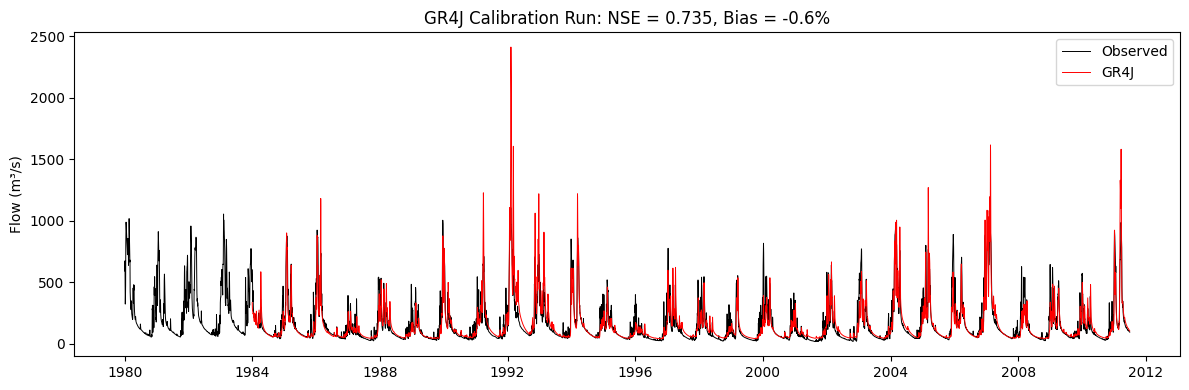

In [20]:
# Performance metrics

valid = (
    np.isfinite(cal_data["Qobs_m3s"])
    & np.isfinite(cal_data["Qsim_m3s"])
)

obs = cal_data.loc[valid, "Qobs_m3s"]
sim = cal_data.loc[valid, "Qsim_m3s"]

nse_gr4j = nse(obs, sim)
bias_gr4j = percent_bias(obs, sim)

# Plot

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    cal_data.index,
    cal_data["Qobs_m3s"],
    color="black",
    linewidth=0.7,
    label="Observed",
)

ax.plot(
    cal_data.index,
    cal_data["Qsim_m3s"],
    color="red",
    linewidth=0.7,
    label="GR4J"
)

ax.set_ylabel("Flow (m³/s)")
ax.set_title(
    f"GR4J Calibration Run: NSE = {nse_gr4j:.3f}, "
    f"Bias = {bias_gr4j:.1f}%"
)

ax.legend()

plt.tight_layout()
plt.show()

---
# **4. Resampling past meteorological data sequences**

4.1. In this step, we will resample the P and PET sequences from our historical data to use them as future climate variability. First, we need to define the **forecast start date** (`fcst_start_date`) and its **range** (`fcst_range`):

In [21]:
# Set forecast start date (YYYY-MM-DD) and range (days)
fcst_start_date = '2025-01-01'
fcst_range = 180 # days

# Converting date from string to datetime
dt_fcst = datetime.strptime(fcst_start_date, '%Y-%m-%d')

4.2. We must search the available historical record for all dates whose calendar day and month match the start date of the forecast.

In [22]:
# Get year, month, and day of the forecast start date
resampling_start_month = dt_fcst.month
resampling_start_year = dt_fcst.year
resampling_start_day = dt_fcst.day

# Find dates of all calendar months and days = forecast date,
# ensuring they do not include the same year of the forecast
start_indices = df_p.index[(df_p.index.month == resampling_start_month) &
                           (df_p.index.day == resampling_start_day) &
                            (df_p.index.year != resampling_start_year)]

print(start_indices)

DatetimeIndex(['1980-01-01', '1981-01-01', '1982-01-01', '1983-01-01',
               '1984-01-01', '1985-01-01', '1986-01-01', '1987-01-01',
               '1988-01-01', '1989-01-01', '1990-01-01', '1991-01-01',
               '1992-01-01', '1993-01-01', '1994-01-01', '1995-01-01',
               '1996-01-01', '1997-01-01', '1998-01-01', '1999-01-01',
               '2000-01-01', '2001-01-01', '2002-01-01', '2003-01-01',
               '2004-01-01', '2005-01-01', '2006-01-01', '2007-01-01',
               '2008-01-01', '2009-01-01', '2010-01-01', '2011-01-01',
               '2012-01-01', '2013-01-01', '2014-01-01', '2015-01-01',
               '2016-01-01', '2017-01-01', '2018-01-01', '2019-01-01',
               '2020-01-01', '2021-01-01', '2022-01-01', '2023-01-01',
               '2024-01-01'],
              dtype='datetime64[ns]', name='Date', freq=None)


4.3. We can build a table containing sequences of length '*fcst_range*' that start on the previously identified dates.

In [23]:
# Get the resampled dates corresponding to forecast calendar dates
resampling_indices = {
    idx.year: pd.date_range(start=idx, periods=fcst_range, freq='D')
    for idx in start_indices}

# Generate sequence of (future) forecast dates
fcst_dates = pd.date_range(start=dt_fcst, periods=fcst_range, freq='D')

# Generate dataframe
df_resampled_dates = pd.DataFrame(resampling_indices, index=fcst_dates)
display(df_resampled_dates)

,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
2025-01-01,1980-01-01,1981-01-01,1982-01-01,1983-01-01,1984-01-01,1985-01-01,1986-01-01,1987-01-01,1988-01-01,1989-01-01,...,2015-01-01,2016-01-01,2017-01-01,2018-01-01,2019-01-01,2020-01-01,2021-01-01,2022-01-01,2023-01-01,2024-01-01
2025-01-02,1980-01-02,1981-01-02,1982-01-02,1983-01-02,1984-01-02,1985-01-02,1986-01-02,1987-01-02,1988-01-02,1989-01-02,...,2015-01-02,2016-01-02,2017-01-02,2018-01-02,2019-01-02,2020-01-02,2021-01-02,2022-01-02,2023-01-02,2024-01-02
2025-01-03,1980-01-03,1981-01-03,1982-01-03,1983-01-03,1984-01-03,1985-01-03,1986-01-03,1987-01-03,1988-01-03,1989-01-03,...,2015-01-03,2016-01-03,2017-01-03,2018-01-03,2019-01-03,2020-01-03,2021-01-03,2022-01-03,2023-01-03,2024-01-03
2025-01-04,1980-01-04,1981-01-04,1982-01-04,1983-01-04,1984-01-04,1985-01-04,1986-01-04,1987-01-04,1988-01-04,1989-01-04,...,2015-01-04,2016-01-04,2017-01-04,2018-01-04,2019-01-04,2020-01-04,2021-01-04,2022-01-04,2023-01-04,2024-01-04
2025-01-05,1980-01-05,1981-01-05,1982-01-05,1983-01-05,1984-01-05,1985-01-05,1986-01-05,1987-01-05,1988-01-05,1989-01-05,...,2015-01-05,2016-01-05,2017-01-05,2018-01-05,2019-01-05,2020-01-05,2021-01-05,2022-01-05,2023-01-05,2024-01-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-06-25,1980-06-24,1981-06-25,1982-06-25,1983-06-25,1984-06-24,1985-06-25,1986-06-25,1987-06-25,1988-06-24,1989-06-25,...,2015-06-25,2016-06-24,2017-06-25,2018-06-25,2019-06-25,2020-06-24,2021-06-25,2022-06-25,2023-06-25,2024-06-24
2025-06-26,1980-06-25,1981-06-26,1982-06-26,1983-06-26,1984-06-25,1985-06-26,1986-06-26,1987-06-26,1988-06-25,1989-06-26,...,2015-06-26,2016-06-25,2017-06-26,2018-06-26,2019-06-26,2020-06-25,2021-06-26,2022-06-26,2023-06-26,2024-06-25
2025-06-27,1980-06-26,1981-06-27,1982-06-27,1983-06-27,1984-06-26,1985-06-27,1986-06-27,1987-06-27,1988-06-26,1989-06-27,...,2015-06-27,2016-06-26,2017-06-27,2018-06-27,2019-06-27,2020-06-26,2021-06-27,2022-06-27,2023-06-27,2024-06-26
2025-06-28,1980-06-27,1981-06-28,1982-06-28,1983-06-28,1984-06-27,1985-06-28,1986-06-28,1987-06-28,1988-06-27,1989-06-28,...,2015-06-28,2016-06-27,2017-06-28,2018-06-28,2019-06-28,2020-06-27,2021-06-28,2022-06-28,2023-06-28,2024-06-27


4.4. We map the values of our daily P and PET time series for the dates previously identified in each sequence.

In [24]:
# Mapping data from time series to their corresponding dates in table
# If dates are not found, fill with NaN values
df_p_resampled = df_resampled_dates.map(lambda t: df_p.loc[t, 'P'] if t in df_p.index else np.nan)
df_pet_resampled = df_resampled_dates.map(lambda t: df_pet.loc[t, 'PET'] if t in df_pet.index else np.nan)

print('Resampled P series:')
display(df_p_resampled)

Resampled P series:


,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
2025-01-01,10.56,25.75,8.37,9.30,5.72,5.48,8.90,3.15,16.97,3.19,...,1.22,0.00,0.00,5.43,17.89,2.73,0.00,27.27,20.58,18.39
2025-01-02,14.64,21.87,19.42,14.92,6.29,3.55,13.33,13.32,23.87,3.33,...,0.00,4.80,0.00,7.25,4.84,24.23,5.81,17.69,9.33,14.91
2025-01-03,4.14,43.64,21.85,20.70,0.24,5.97,12.50,5.21,4.28,5.73,...,2.55,3.69,0.00,6.68,4.22,17.67,2.58,24.13,13.44,25.27
2025-01-04,0.52,4.02,16.18,8.49,0.22,13.30,17.63,0.42,19.89,26.59,...,8.63,10.79,0.93,19.05,0.37,20.82,7.44,22.88,5.36,45.87
2025-01-05,0.10,1.00,12.58,20.97,4.49,28.41,13.58,0.00,6.56,13.44,...,3.31,8.37,11.22,33.12,0.36,1.96,1.49,16.55,20.24,23.36
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-06-25,0.36,0.00,0.00,0.00,0.00,0.00,0.00,0.11,0.00,0.38,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2025-06-26,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.27,5.10,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2025-06-27,0.84,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.01,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2025-06-28,21.58,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


4.5. Finally, we must exclude any resampled sequence that, for any reason, contains invalid data (NaN values).

In [25]:
# Check if there are missing values
fcst_p_missing = np.isnan(df_p_resampled).sum(axis=0)
fcst_pet_missing = np.isnan(df_pet_resampled).sum(axis=0)

# If there are years with missing data either in forecast p or pet, drop them
missing_years = fcst_p_missing + fcst_pet_missing
if missing_years.sum() > 0:
    idx = missing_years[missing_years > 0].index
    df_p_resampled = df_p_resampled.drop(idx, axis=1)
    df_pet_resampled = df_pet_resampled.drop(idx, axis=1)


---

# **5. Generate ESP Forecast**

5.1. Before running the model, we must extract precipitation and PET for the warmup period before the forecast. We do this by extracting the last year of observed P and PET, which we will add to the start of each historical precipitation sequence to ensure model conditions are correct before the forecast begins.

In [26]:
warmup_p = data['P'][-warmup_length:]
warmup_pet = data['PET'][-warmup_length:]

5.2. Using the updated initial conditions, we run the model with each of the historical precipitation sequences previously selected, generating the ESP forecast (with daily streamflows).

In [27]:

# Initializing Q forecast variable
q_fcst = np.zeros((fcst_range, df_p_resampled.shape[1]))

# Run model for each ensemble member (year)
for m, col in enumerate(df_p_resampled.columns):

    results = run_gr4j(
        p=np.append(warmup_p.values, df_p_resampled[col].values),
        pet=np.append(warmup_pet.values, df_pet_resampled[col].values),
        parameters=best_parameters,
        warmup_length=warmup_length,
    )

    results_m3s = mmday_to_m3s(
        results,
        catchment_area,
    )

    # Store streamflow for each ensemble member
    q_fcst[:,m] = results_m3s[:]

# Convert ensemble forecast from array to DataFrame
df_fcst = pd.DataFrame(q_fcst, index=df_p_resampled.index, columns=df_p_resampled.columns)

display(df_fcst)

/usr/local/lib/python3.13/dist-packages/hydromodel/models/gr4j.py:401: RuntimeWarning: Parameter metadata for model 'gr4j' was not provided. Falling back to MODEL_PARAM_DICT defaults.
  model_param_dict = get_model_param_config("gr4j", kwargs)


,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
2025-01-01,122.129902,123.405798,122.095829,122.012683,121.684482,121.684641,121.956468,121.684445,122.564346,121.684223,...,121.684105,121.684035,121.683982,121.684587,122.560648,121.684206,121.684106,123.458007,122.762723,122.741838
2025-01-02,121.432888,128.328773,121.667741,120.835504,118.437506,118.438281,120.285151,118.855280,124.229924,118.435684,...,118.434743,118.434697,118.434006,118.506851,122.685195,119.792759,118.435169,128.066310,123.729128,124.476685
2025-01-03,124.506405,145.283097,127.357400,124.269196,115.545015,115.547328,121.624497,117.569837,132.658487,115.659265,...,115.535529,115.536835,115.533089,115.907891,125.196756,123.005418,115.538076,141.669810,128.334678,133.410749
2025-01-04,130.877901,179.650675,141.977692,134.499362,113.024661,113.552697,127.598510,117.620901,148.287807,115.067910,...,113.026899,113.599176,112.996151,115.017825,129.998368,133.541918,113.186190,168.234639,137.552157,156.188022
2025-01-05,140.495144,230.985355,167.770345,153.156611,110.894634,115.254970,140.412022,118.965014,173.564833,120.193249,...,110.970809,113.994859,110.954418,120.168414,137.126457,153.247112,111.721967,211.742825,152.412021,201.369485
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-06-25,98.685390,104.276328,127.570969,154.285992,56.401060,80.102278,63.379834,61.834481,75.603543,55.659824,...,85.142214,60.921472,55.342715,62.343771,73.618641,94.032716,54.769101,65.498745,58.828303,75.004599
2025-06-26,97.874243,102.899204,125.891778,152.634215,56.109118,79.539451,63.024388,61.456290,75.006221,55.502932,...,84.285246,60.592425,55.065827,61.976154,72.931750,93.094398,54.521388,65.090606,58.531416,74.445738
2025-06-27,97.084021,101.573512,124.269560,151.011308,55.822834,78.988615,62.674457,61.087296,74.422468,55.608289,...,83.451179,60.267728,54.793659,61.616076,72.264404,92.178517,54.277729,64.690406,58.239124,73.897903
2025-06-28,98.427938,100.296603,122.700009,149.417465,55.542093,78.448017,62.331138,60.727712,73.851224,55.910381,...,82.638496,59.947080,54.526368,61.262510,71.616535,91.285087,54.037894,64.297749,57.951834,73.361320


5.3. Aggregating the daily streamflow forecast series into monthly averages:

In [28]:
# Resampling forecast from daily to monthly time step
df_forecast_month = df_fcst.resample('MS').mean()
df_forecast_month.columns = [f'M{i}' for i in range(1, df_fcst.columns.size+1)]
df_forecast_month.index.name = 'Date'

5.4. Plotting the final forecast chart.

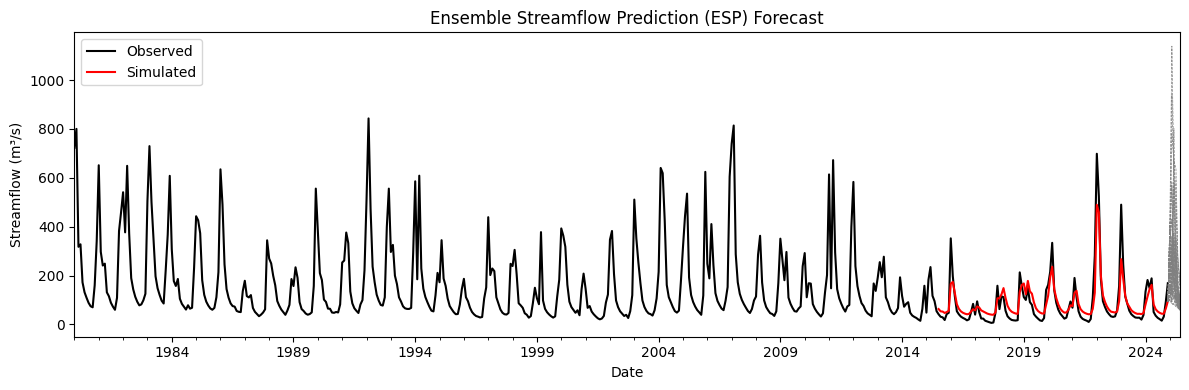

In [29]:
#@title Plot
# Resample daily observed and simulated to monthly time step
df_month = df_q.resample('MS').mean()
df_month_sim = val_data['Qsim_m3s'].resample('MS').mean()

# This part is only for visualization purposes
# Creating continuity between simulation and forecast traces
start_dt = df_forecast_month.index[0] + pd.tseries.offsets.DateOffset(months=-1)
df_last_sim = pd.DataFrame(df_month_sim[start_dt].repeat(df_forecast_month.shape[1])).T
df_last_sim['Date'] = start_dt
df_last_sim.set_index('Date', inplace=True)
df_last_sim.columns = [f'M{i}' for i in range(1, df_fcst.columns.size+1)]
df_forecast_plot = pd.concat([df_last_sim, df_forecast_month], axis=0)

# Plot on screen
fig, ax = plt.subplots(figsize=(12, 4))

df_month.plot(ax=ax, color='k')
df_month_sim.plot(ax=ax, color='r')
df_forecast_plot.plot(ax=ax, color='gray', linestyle='--', linewidth=0.5, legend=False)
ax.set_ylabel('Streamflow (m³/s)')
ax.set_title('Ensemble Streamflow Prediction (ESP) Forecast')

plt.legend(['Observed', 'Simulated'])
plt.tight_layout()
plt.show()

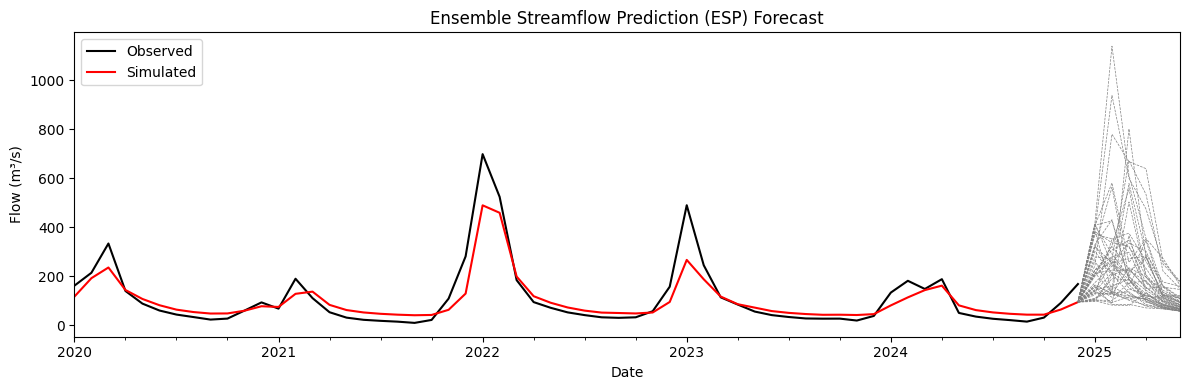

In [30]:
#@title Plot
# Resample daily observed and simulated to monthly time step
df_month = df_q.resample('MS').mean()
df_month_sim = val_data['Qsim_m3s'].resample('MS').mean()

# This part is only for visualization purposes
# Creating continuity between simulation and forecast traces
start_dt = df_forecast_month.index[0] + pd.tseries.offsets.DateOffset(months=-1)
df_last_sim = pd.DataFrame(df_month_sim[start_dt].repeat(df_forecast_month.shape[1])).T
df_last_sim['Date'] = start_dt
df_last_sim.set_index('Date', inplace=True)
df_last_sim.columns = [f'M{i}' for i in range(1, df_fcst.columns.size+1)]
df_forecast_plot = pd.concat([df_last_sim, df_forecast_month], axis=0)

df_month = df_month[df_month.index>='01-01-2020']
df_month_sim = df_month_sim[df_month_sim.index>='01-01-2020']

# Plot on screen
fig, ax = plt.subplots(figsize=(12, 4))

df_month.plot(ax=ax, color='k')
df_month_sim.plot(ax=ax, color='r')
df_forecast_plot.plot(ax=ax, color='gray', linestyle='--', linewidth=0.5, legend=False)
ax.set_ylabel('Flow (m³/s)')
ax.set_title('Ensemble Streamflow Prediction (ESP) Forecast')

plt.legend(['Observed', 'Simulated'])
plt.tight_layout()
plt.show()

---

# **6. Export the generated forecast**

Finally, we can export our streamflow forecasts to the specified output folder. The resulting file will contain multiple columns corresponding to the ESP ensemble members (M1, M2, M3, ..., etc.).

In [31]:
# Save to CSV
file_name = Path(file_Q_path).stem
df_forecast_month.to_csv(f'{folder_output}/ESP_{file_name}_{fcst_start_date}.csv', float_format='%.2f')